In [1]:
from pathlib import Path
import sys
import mlflow
import sklearn

PROJECT_ROOT = Path.home() / "workspace" / "mlops-assignment"

print("Python:", sys.version)
print("Project root:", PROJECT_ROOT)
print("Dataset exists:", (PROJECT_ROOT / "data" / "heart_disease_raw_with_target.csv").exists())
print("MLflow database exists:", (PROJECT_ROOT / "mlflow.db").exists())
print("MLflow:", mlflow.__version__)
print("Scikit-learn:", sklearn.__version__)

/home/cloud/miniconda3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]
Project root: /home/s2025ae05376/workspace/mlops-assignment
Dataset exists: True
MLflow database exists: True
MLflow: 3.17.0
Scikit-learn: 1.9.1


In [2]:
import sys
import pandas as pd
import numpy as np
import sklearn
import mlflow

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)

Python: 3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
MLflow: 3.17.0


In [3]:

import json
from pathlib import Path

notebook_path = PROJECT_ROOT / "notebooks" / "01_EDA_Model_Development.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))
print("Code cells:", sum(c["cell_type"] == "code" for c in nb["cells"]))
print("Markdown cells:", sum(c["cell_type"] == "markdown" for c in nb["cells"]))

print("\n--- Saved cell overview ---")
for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if cell["cell_type"] == "code":
        outputs = cell.get("outputs", [])
        errors = [
            out.get("ename", "") + ": " + out.get("evalue", "")
            for out in outputs if out.get("output_type") == "error"
        ]
        status = "ERROR SAVED" if errors else (
            "OUTPUT SAVED" if outputs else "NO SAVED OUTPUT"
        )
        print(f"Cell {i}: {status} | {source[:100].replace(chr(10), ' ')}")
        for err in errors:
            print("  ", err)
    else:
        print(f"Cell {i}: MARKDOWN | {source[:80].replace(chr(10), ' ')}")


Total cells: 75
Code cells: 70
Markdown cells: 5

--- Saved cell overview ---
Cell 0: OUTPUT SAVED | from pathlib import Path import sys import mlflow import sklearn  PROJECT_ROOT = Path.home() / "work
Cell 1: OUTPUT SAVED | import sys import pandas as pd import numpy as np import sklearn import mlflow  print("Python:", sys
Cell 2: OUTPUT SAVED |  import json from pathlib import Path  notebook_path = PROJECT_ROOT / "notebooks" / "01_EDA_Model_De
Cell 3: OUTPUT SAVED | import sys import pandas as pd import numpy as np import sklearn import mlflow  print("Python:", sys
Cell 4: MARKDOWN | # MLOps Assignment 01 ## Heart Disease Prediction — EDA and Model Development  #
Cell 5: OUTPUT SAVED | import warnings warnings.filterwarnings("ignore")  import numpy as np import pandas as pd import mat
Cell 6: OUTPUT SAVED | # Fetch the UCI Heart Disease dataset heart_disease = fetch_ucirepo(id=45)  # Separate features and 
Cell 7: OUTPUT SAVED | X.head()
Cell 8: OUTPUT SAVED | X.info()
Cell 9: OUTPUT

In [4]:
import sys
import pandas as pd
import numpy as np
import sklearn
import mlflow

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("MLflow:", mlflow.__version__)

Python: 3.12.9 | packaged by Anaconda, Inc. | (main, Feb  6 2025, 18:56:27) [GCC 11.2.0]
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
MLflow: 3.17.0


# MLOps Assignment 01
## Heart Disease Prediction — EDA and Model Development

### Objective

Develop a reproducible machine learning solution for predicting the presence
of heart disease using the UCI Heart Disease dataset.

This notebook covers:

1. Data acquisition
2. Data inspection and cleaning
3. Exploratory Data Analysis (EDA)
4. Feature engineering
5. Train-test split
6. Logistic Regression
7. Random Forest
8. Cross-validation
9. Model evaluation

The final model will later be integrated with MLflow, CI/CD, Docker,
Kubernetes deployment, and monitoring.

In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("Libraries imported successfully.")

Libraries imported successfully.


In [6]:
# Fetch the UCI Heart Disease dataset
heart_disease = fetch_ucirepo(id=45)

# Separate features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303, 1)


In [7]:
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [8]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


In [9]:
y.head()

,num
0,0
1,2
2,1
3,0
4,0


In [10]:
y.value_counts()

num
0      164
1       55
2       36
3       35
4       13
Name: count, dtype: int64

In [11]:
df = pd.concat([X, y], axis=1)

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [12]:
df.columns.tolist()

['age',
 'sex',
 'cp',
 'trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalach',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal',
 'num']

In [13]:
print(f"Number of rows    : {df.shape[0]}")
print(f"Number of columns : {df.shape[1]}")

Number of rows    : 303
Number of columns : 14


In [14]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

ca      4
thal    2
dtype: int64

In [15]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_summary[missing_summary["Missing Count"] > 0]

,Missing Count,Missing Percentage
ca,4,1.320132
thal,2,0.660066


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
print("Target distribution:")
print(y.iloc[:, 0].value_counts().sort_index())

Target distribution:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [18]:
# Preserve the original target
df["target_original"] = df["num"]

# Convert the original multi-class target into binary classification
df["target"] = (df["num"] > 0).astype(int)

# Check the new target distribution
print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [19]:
target_distribution = df["target"].value_counts().sort_index()
target_percentage = df["target"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_distribution,
    "Percentage": target_percentage.round(2)
})

target_summary

,Count,Percentage
target,,
0,164,54.13
1,139,45.87


In [20]:
data_quality = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

data_quality

,Data Type,Missing Values,Missing %,Unique Values
age,int64,0,0.00,41
sex,int64,0,0.00,2
cp,int64,0,0.00,4
trestbps,int64,0,0.00,50
chol,int64,0,0.00,152
fbs,int64,0,0.00,2
restecg,int64,0,0.00,3
thalach,int64,0,0.00,91
exang,int64,0,0.00,2
oldpeak,float64,0,0.00,40


In [21]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


## 4. Target Class Distribution

The original UCI target contains five values (0–4). For this binary
classification problem, values 1–4 are combined into the positive class,
representing the presence of heart disease.

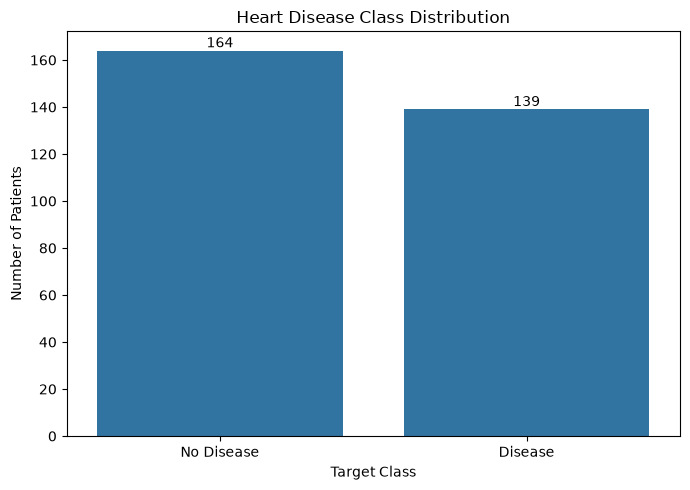

In [22]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="target"
)

plt.title("Heart Disease Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Patients")
plt.xticks([0, 1], ["No Disease", "Disease"])

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

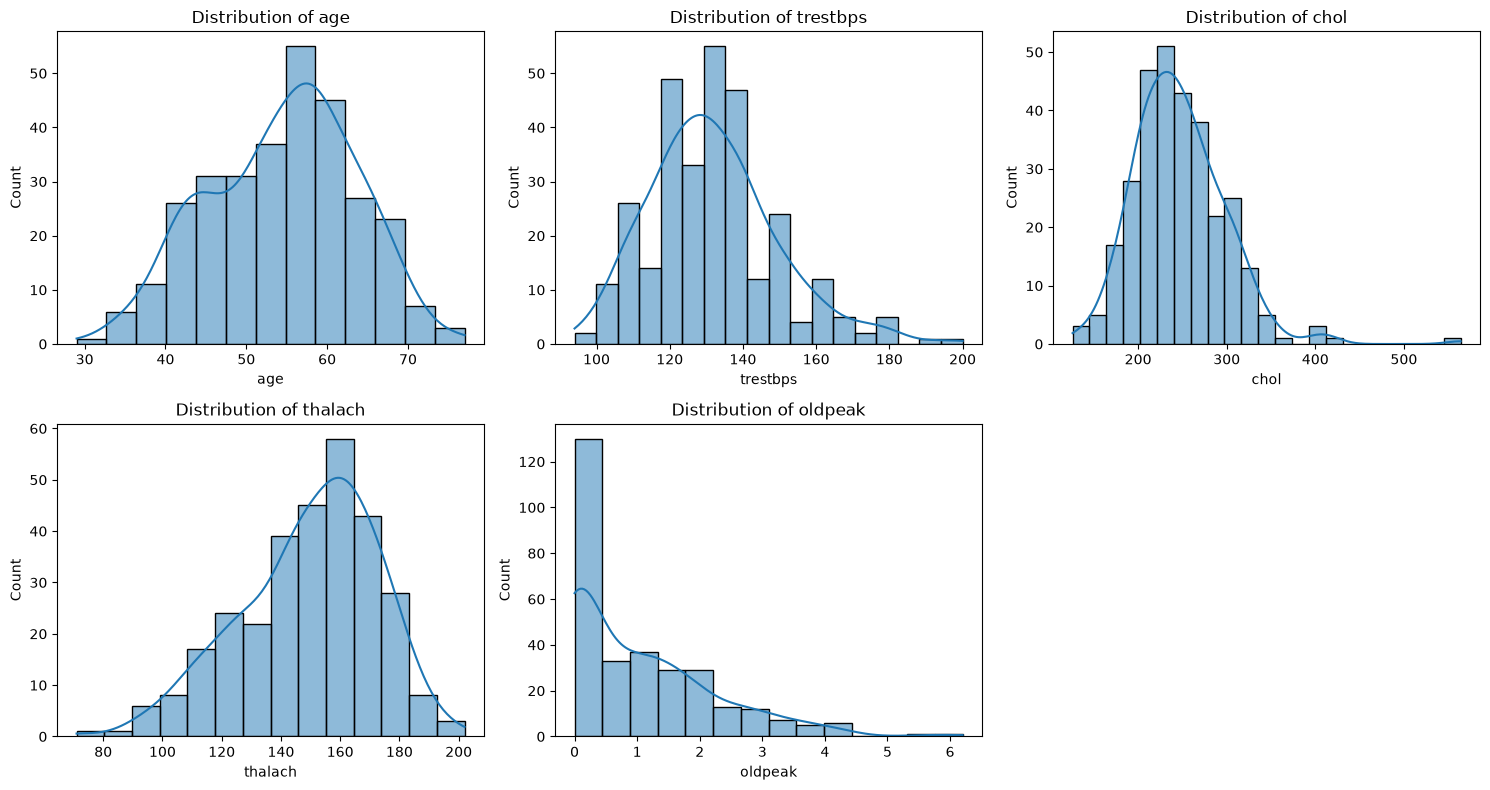

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flatten(), numerical_features):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")

# Hide unused subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

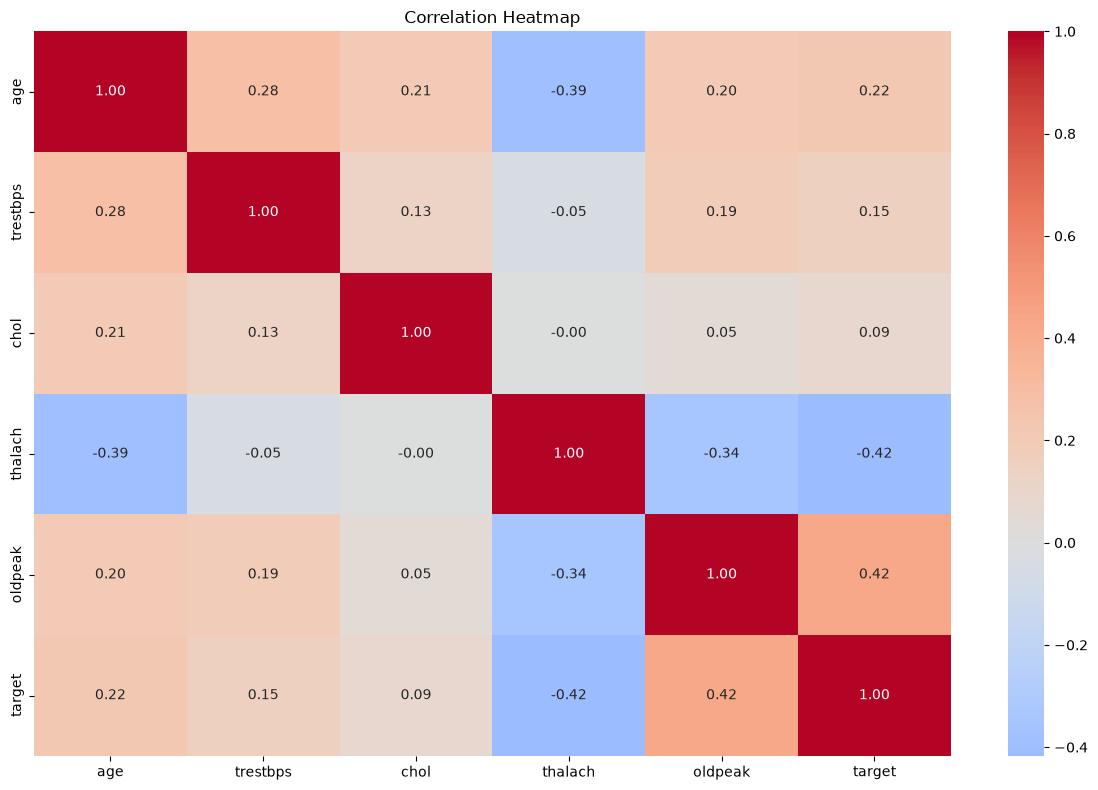

In [24]:
plt.figure(figsize=(12, 8))

correlation_matrix = df[numerical_features + ["target"]].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

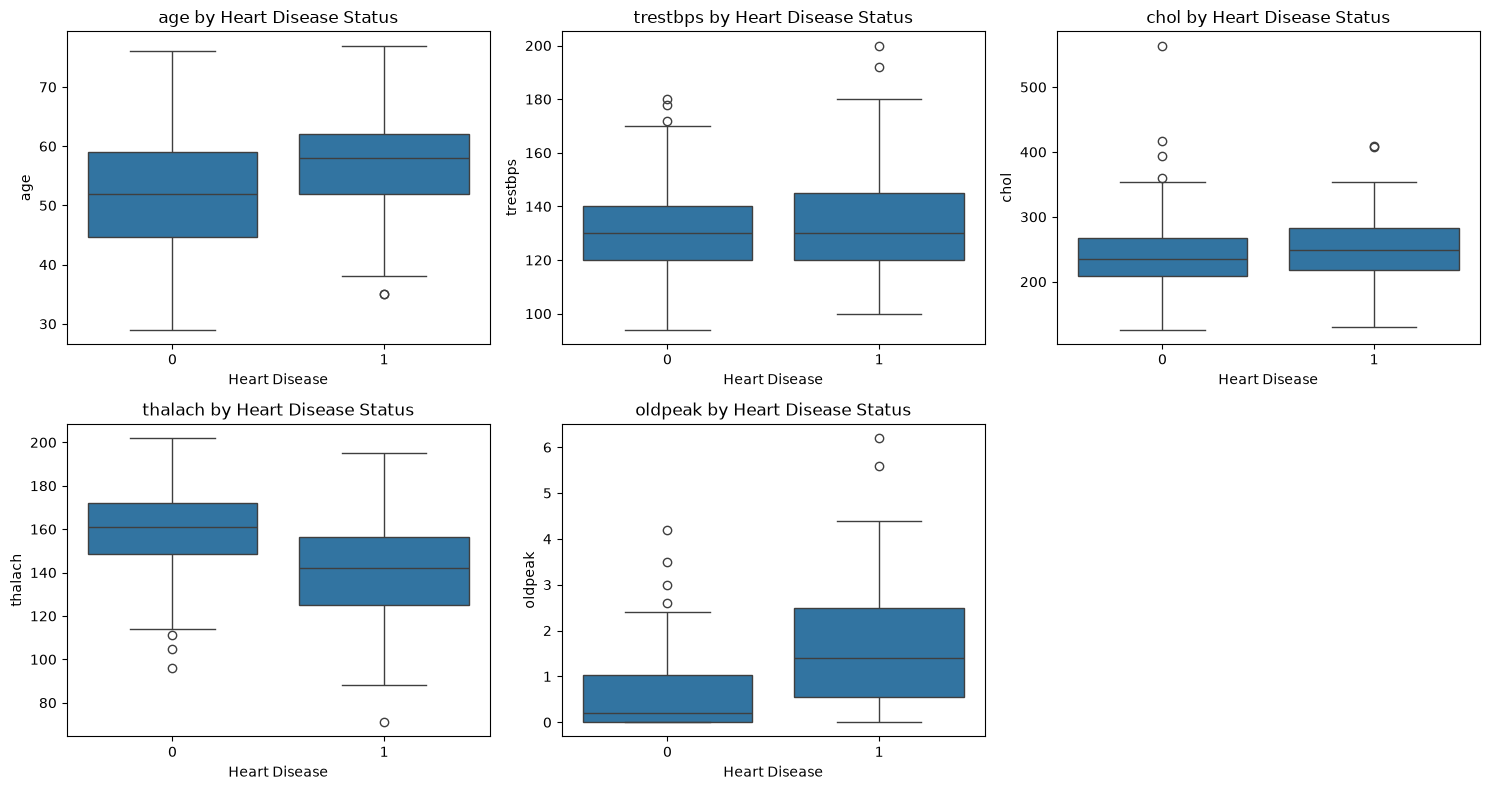

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flatten(), numerical_features):
    sns.boxplot(
        data=df,
        x="target",
        y=column,
        ax=ax
    )
    ax.set_title(f"{column} by Heart Disease Status")
    ax.set_xlabel("Heart Disease")

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

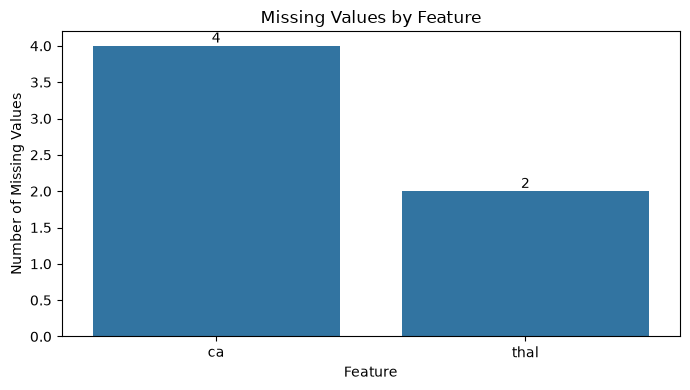

In [26]:
missing_plot = df.isnull().sum()
missing_plot = missing_plot[missing_plot > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=missing_plot.index,
    y=missing_plot.values
)

plt.title("Missing Values by Feature")
plt.xlabel("Feature")
plt.ylabel("Number of Missing Values")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [27]:
import os

os.makedirs("../data", exist_ok=True)

df.to_csv("../data/heart_disease_raw_with_target.csv", index=False)

print("Raw dataset saved successfully.")

Raw dataset saved successfully.


# 5. Feature Engineering and Model Development

The original UCI target contains five values (0–4). For this binary
classification task, values greater than 0 are mapped to class 1.

The original target columns are excluded from the feature matrix to prevent
target leakage.

In [28]:
# Define the final feature matrix and binary target

feature_columns = numerical_features + categorical_features

X = df[feature_columns].copy()
y = df["target"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature matrix shape: (303, 13)
Target shape: (303,)

Features:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Target distribution:
target
0    164
1    139
Name: count, dtype: int64


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 242
Test samples: 61

Training target distribution:
target
0    0.541322
1    0.458678
Name: proportion, dtype: float64

Test target distribution:
target
0    0.540984
1    0.459016
Name: proportion, dtype: float64


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [31]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [32]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [34]:
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [35]:
logreg_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

In [37]:
rf_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [39]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

In [40]:
logreg_cv = cross_validate(
    logreg_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

logreg_cv_results = {
    metric: logreg_cv[f"test_{metric}"].mean()
    for metric in scoring
}

logreg_cv_results

{'accuracy': np.float64(0.8471088435374149),
 'precision': np.float64(0.8767529146045769),
 'recall': np.float64(0.783399209486166),
 'roc_auc': np.float64(0.9024931590148981)}

In [41]:
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv_results = {
    metric: rf_cv[f"test_{metric}"].mean()
    for metric in scoring
}

rf_cv_results

{'accuracy': np.float64(0.8016156462585033),
 'precision': np.float64(0.7788378288378289),
 'recall': np.float64(0.800790513833992),
 'roc_auc': np.float64(0.8985113115547897)}

In [42]:
cv_results = pd.DataFrame(
    [logreg_cv_results, rf_cv_results],
    index=["Logistic Regression", "Random Forest"]
)

cv_results.round(4)

,accuracy,precision,recall,roc_auc
Logistic Regression,0.8471,0.8768,0.7834,0.9025
Random Forest,0.8016,0.7788,0.8008,0.8985


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [44]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    return results

In [45]:
logreg_test_results = evaluate_model(
    logreg_pipeline,
    X_test,
    y_test
)

rf_test_results = evaluate_model(
    rf_pipeline,
    X_test,
    y_test
)

test_results = pd.DataFrame(
    [logreg_test_results, rf_test_results],
    index=["Logistic Regression", "Random Forest"]
)

test_results.round(4)

,Accuracy,Precision,Recall,ROC-AUC
Logistic Regression,0.8852,0.8387,0.9286,0.9665
Random Forest,0.8852,0.8182,0.9643,0.9464


In [46]:
logreg_predictions = logreg_pipeline.predict(X_test)

print("Logistic Regression")
print(
    classification_report(
        y_test,
        logreg_predictions,
        target_names=["No Disease", "Disease"]
    )
)

Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [47]:
rf_predictions = rf_pipeline.predict(X_test)

print("Random Forest")
print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["No Disease", "Disease"]
    )
)

Random Forest
              precision    recall  f1-score   support

  No Disease       0.96      0.82      0.89        33
     Disease       0.82      0.96      0.89        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.90      0.89      0.89        61



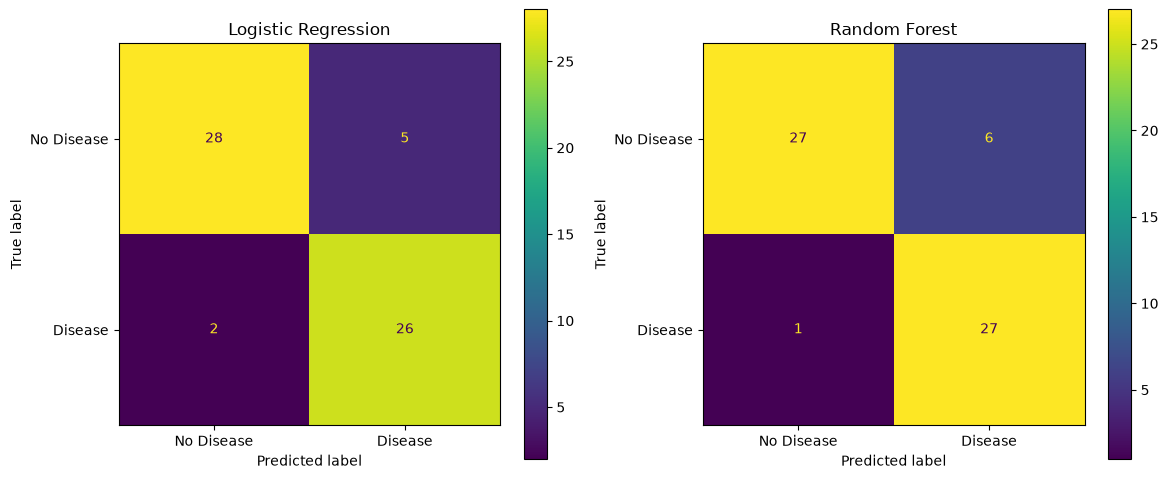

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, logreg_predictions),
    display_labels=["No Disease", "Disease"]
).plot(ax=axes[0], values_format="d")

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_predictions),
    display_labels=["No Disease", "Disease"]
).plot(ax=axes[1], values_format="d")

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

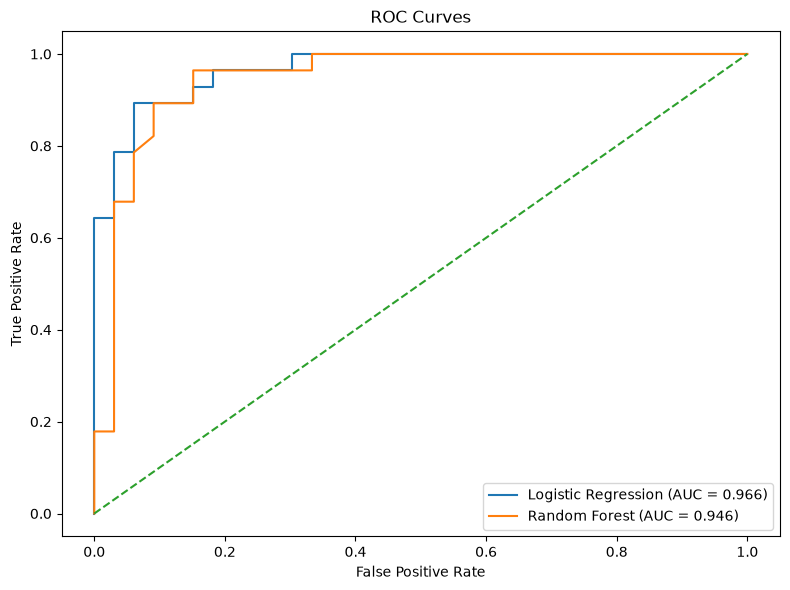

In [49]:
from sklearn.metrics import roc_curve

logreg_probabilities = logreg_pipeline.predict_proba(X_test)[:, 1]
rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

logreg_fpr, logreg_tpr, _ = roc_curve(
    y_test,
    logreg_probabilities
)

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    logreg_fpr,
    logreg_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logreg_probabilities):.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probabilities):.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

In [50]:
display(cv_results.round(4))
display(test_results.round(4))

,accuracy,precision,recall,roc_auc
Logistic Regression,0.8471,0.8768,0.7834,0.9025
Random Forest,0.8016,0.7788,0.8008,0.8985


,Accuracy,Precision,Recall,ROC-AUC
Logistic Regression,0.8852,0.8387,0.9286,0.9665
Random Forest,0.8852,0.8182,0.9643,0.9464


# 6. Experiment Tracking with MLflow

MLflow is used to track model experiments, including model parameters,
cross-validation metrics, test metrics, evaluation plots, and the trained
model artifact.

Two baseline classification experiments are tracked:
1. Logistic Regression
2. Random Forest

In [51]:
import mlflow
import mlflow.sklearn
from pathlib import Path

# Use the actual project directory
PROJECT_ROOT = Path.home() / "workspace" / "mlops-assignment"

# Use the database inside that project
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"
assert MLFLOW_DB.exists(), f"MLflow database not found: {MLFLOW_DB}"

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB}")

# Use the existing experiment name
EXPERIMENT_NAME = "heart-disease-classification-linux"

print("Project root:", PROJECT_ROOT)
print("Database:", MLFLOW_DB)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME)

Project root: /home/s2025ae05376/workspace/mlops-assignment
Database: /home/s2025ae05376/workspace/mlops-assignment/mlflow.db
Tracking URI: sqlite:////home/s2025ae05376/workspace/mlops-assignment/mlflow.db
Experiment: heart-disease-classification-linux


In [52]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()

print("Experiment:")
experiment = client.get_experiment_by_name(
    "heart-disease-classification-linux"
)
print(experiment)

print("\nExisting Logistic Regression run:")
try:
    print(client.get_run("9111018bddac4c858b22b276a36f0310").info.run_id)
except Exception as e:
    print("NOT FOUND:", e)

print("\nExisting Random Forest run:")
try:
    print(client.get_run("9c5d802f680f42f0a0274a6115e0c622").info.run_id)
except Exception as e:
    print("NOT FOUND:", e)

Experiment:
<Experiment: artifact_location='file:///home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/runs', creation_time=1791643710909, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791643710909, lifecycle_stage='active', name='heart-disease-classification-linux', tags={}, trace_location=None, workspace='default'>

Existing Logistic Regression run:
9111018bddac4c858b22b276a36f0310

Existing Random Forest run:
9c5d802f680f42f0a0274a6115e0c622


In [53]:
def get_model_metrics(model, X_data, y_data):
    predictions = model.predict(X_data)
    probabilities = model.predict_proba(X_data)[:, 1]

    return {
        "accuracy": accuracy_score(y_data, predictions),
        "precision": precision_score(y_data, predictions),
        "recall": recall_score(y_data, predictions),
        "roc_auc": roc_auc_score(y_data, probabilities)
    }

In [54]:
from pathlib import Path
import mlflow
from mlflow.tracking import MlflowClient

project = Path.home() / "workspace" / "mlops-assignment"
client = MlflowClient()

print("Project exists:", project.exists())
print("Tracking URI:", mlflow.get_tracking_uri())

experiment = client.get_experiment_by_name(
    "heart-disease-classification-linux"
)
print("Experiment artifact location:", experiment.artifact_location)

run_id = "9111018bddac4c858b22b276a36f0310"
run = client.get_run(run_id)
print("Run artifact URI:", run.info.artifact_uri)

Project exists: True
Tracking URI: sqlite:////home/s2025ae05376/workspace/mlops-assignment/mlflow.db
Experiment artifact location: file:///home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/runs
Run artifact URI: file:///home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/runs/9111018bddac4c858b22b276a36f0310/artifacts


In [55]:
print("Model class:", type(logreg_pipeline))
print("Pipeline steps:", logreg_pipeline.named_steps.keys())

from pathlib import Path

project = Path.home() / "workspace" / "mlops-assignment"
print("Project path:", project)
print("Model output directory exists:", (project / "models").exists())

Model class: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: dict_keys(['preprocessor', 'model'])
Project path: /home/s2025ae05376/workspace/mlops-assignment
Model output directory exists: True


In [58]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()
run_id = "9111018bddac4c858b22b276a36f0310"

run = client.get_run(run_id)

print("Run ID:", run.info.run_id)
print("Run status:", run.info.status)
print("Run artifact URI:", run.info.artifact_uri)
print("Model-related tags:")

for key, value in run.data.tags.items():
    if "model" in key.lower() or "source" in key.lower():
        print(f"{key}: {value}")

print("\nMLflow version:", mlflow.__version__)
mlflow.set_experiment(EXPERIMENT_NAME)

Run ID: 9111018bddac4c858b22b276a36f0310
Run status: FINISHED
Run artifact URI: file:///home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/runs/9111018bddac4c858b22b276a36f0310/artifacts
Model-related tags:
mlflow.source.name: -
mlflow.source.type: LOCAL

MLflow version: 3.17.0


<Experiment: artifact_location='file:///home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/runs', creation_time=1791643710909, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1791643710909, lifecycle_stage='active', name='heart-disease-classification-linux', tags={}, trace_location=None, workspace='default'>

In [59]:
with mlflow.start_run(run_name="logistic_regression_baseline"):

    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)

    for metric, value in logreg_cv_results.items():
        mlflow.log_metric(
            f"cv_{metric}",
            float(value)
        )

    logreg_metrics = get_model_metrics(
        logreg_pipeline,
        X_test,
        y_test
    )

    for metric, value in logreg_metrics.items():
        mlflow.log_metric(
            f"test_{metric}",
            float(value)
        )

    mlflow.sklearn.log_model(
        sk_model=logreg_pipeline,
        artifact_path="model",
        serialization_format="pickle"
    )

    print("Logistic Regression run logged successfully.")

2026/10/11 21:28:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/11 21:28:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression run logged successfully.


In [60]:
with mlflow.start_run(run_name="random_forest_baseline"):

    mlflow.log_param("model_type", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("class_weight", "balanced")

    for metric, value in rf_cv_results.items():
        mlflow.log_metric(
            f"cv_{metric}",
            float(value)
        )

    rf_metrics = get_model_metrics(
        rf_pipeline,
        X_test,
        y_test
    )

    for metric, value in rf_metrics.items():
        mlflow.log_metric(
            f"test_{metric}",
            float(value)
        )

    mlflow.sklearn.log_model(
        rf_pipeline,
        name="model",
        serialization_format="pickle"
    )

    print("Random Forest run logged successfully.")

2026/10/11 21:28:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest run logged successfully.


In [61]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME]
)

runs[
    [
        "run_id",
        "tags.mlflow.runName",
        "params.model_type",
        "metrics.cv_accuracy",
        "metrics.cv_precision",
        "metrics.cv_recall",
        "metrics.cv_roc_auc",
        "metrics.test_accuracy",
        "metrics.test_precision",
        "metrics.test_recall",
        "metrics.test_roc_auc"
    ]
]

,run_id,tags.mlflow.runName,params.model_type,metrics.cv_accuracy,metrics.cv_precision,metrics.cv_recall,metrics.cv_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc
0,94e10ee1eaa54f7aa415189f727877af,random_forest_baseline,RandomForestClassifier,0.801616,0.778838,0.800791,0.898511,0.885246,0.818182,0.964286,0.946429
1,46ecf22b046e4ecf9950614ec79f421e,logistic_regression_baseline,LogisticRegression,0.847109,0.876753,0.783399,0.902493,0.885246,0.838710,0.928571,0.966450
2,07b275b7351e46bea0f25d06a58b2430,tuning_grid_search_random_forest,random_forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,30af5bb5d3f64d0ba13927705dee92b4,tuning_grid_search_logistic_regression,logistic_regression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9c5d802f680f42f0a0274a6115e0c622,random_forest_final,RandomForestClassifier,NaN,NaN,NaN,NaN,0.885246,0.818182,0.964286,0.946429
5,9111018bddac4c858b22b276a36f0310,logistic_regression_final,LogisticRegression,NaN,NaN,NaN,NaN,0.885246,0.838710,0.928571,0.966450


In [62]:
from pathlib import Path

ARTIFACT_DIR = PROJECT_ROOT / "mlflow_artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("Artifact directory:", ARTIFACT_DIR)

Artifact directory: /home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts


In [63]:
logreg_cm_path = ARTIFACT_DIR / "logreg_confusion_matrix.png"

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, logreg_predictions),
    display_labels=["No Disease", "Disease"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Logistic Regression - Confusion Matrix")

plt.tight_layout()
fig.savefig(logreg_cm_path, dpi=150)
plt.close(fig)

print("Saved:", logreg_cm_path)

Saved: /home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/logreg_confusion_matrix.png


In [64]:
rf_cm_path = ARTIFACT_DIR / "rf_confusion_matrix.png"

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_predictions),
    display_labels=["No Disease", "Disease"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Random Forest - Confusion Matrix")

plt.tight_layout()
fig.savefig(rf_cm_path, dpi=150)
plt.close(fig)

print("Saved:", rf_cm_path)

Saved: /home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/rf_confusion_matrix.png


In [65]:
roc_path = ARTIFACT_DIR / "roc_curves.png"

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    logreg_fpr,
    logreg_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, logreg_probabilities):.3f})"
)

ax.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probabilities):.3f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison")
ax.legend()

plt.tight_layout()
fig.savefig(roc_path, dpi=150)
plt.close(fig)

print("Saved:", roc_path)

Saved: /home/s2025ae05376/workspace/mlops-assignment/mlflow_artifacts/roc_curves.png


In [66]:
with mlflow.start_run(run_name="logistic_regression_final"):

    # Parameters
    mlflow.log_param("model_type", "LogisticRegression")
    mlflow.log_param("max_iter", 1000)
    mlflow.log_param("random_state", 42)

    # CV metrics
    for metric, value in logreg_cv_results.items():
        mlflow.log_metric(
            f"cv_{metric}",
            float(value)
        )

    # Test metrics
    for metric, value in logreg_metrics.items():
        mlflow.log_metric(
            f"test_{metric}",
            float(value)
        )

    # Model
    mlflow.sklearn.log_model(
        logreg_pipeline,
        name="model",
        serialization_format="pickle"
    )

    # Artifacts
    mlflow.log_artifact(
        str(logreg_cm_path),
        artifact_path="plots"
    )

    mlflow.log_artifact(
        str(roc_path),
        artifact_path="plots"
    )

    print("Final Logistic Regression experiment logged.")

2026/10/11 21:29:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Final Logistic Regression experiment logged.


In [67]:
with mlflow.start_run(run_name="random_forest_final"):

    # Parameters
    mlflow.log_param("model_type", "RandomForestClassifier")
    mlflow.log_param("n_estimators", 300)
    mlflow.log_param("random_state", 42)
    mlflow.log_param("class_weight", "balanced")

    # CV metrics
    for metric, value in rf_cv_results.items():
        mlflow.log_metric(
            f"cv_{metric}",
            float(value)
        )

    # Test metrics
    for metric, value in rf_metrics.items():
        mlflow.log_metric(
            f"test_{metric}",
            float(value)
        )

    # Model
    mlflow.sklearn.log_model(
        rf_pipeline,
        name="model",
        serialization_format="pickle"
    )

    # Artifacts
    mlflow.log_artifact(
        str(rf_cm_path),
        artifact_path="plots"
    )

    mlflow.log_artifact(
        str(roc_path),
        artifact_path="plots"
    )

    print("Final Random Forest experiment logged.")

2026/10/11 21:29:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Final Random Forest experiment logged.


In [68]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME]
)

runs[
    [
        "run_id",
        "tags.mlflow.runName",
        "params.model_type",
        "metrics.cv_accuracy",
        "metrics.cv_precision",
        "metrics.cv_recall",
        "metrics.cv_roc_auc",
        "metrics.test_accuracy",
        "metrics.test_precision",
        "metrics.test_recall",
        "metrics.test_roc_auc"
    ]
]

,run_id,tags.mlflow.runName,params.model_type,metrics.cv_accuracy,metrics.cv_precision,metrics.cv_recall,metrics.cv_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc
0,9fc47f2e0a304cf0a5b1754e32d6c5e9,random_forest_final,RandomForestClassifier,0.801616,0.778838,0.800791,0.898511,0.885246,0.818182,0.964286,0.946429
1,22519b97d51b40008c081249a318bb93,logistic_regression_final,LogisticRegression,0.847109,0.876753,0.783399,0.902493,0.885246,0.838710,0.928571,0.966450
2,94e10ee1eaa54f7aa415189f727877af,random_forest_baseline,RandomForestClassifier,0.801616,0.778838,0.800791,0.898511,0.885246,0.818182,0.964286,0.946429
3,46ecf22b046e4ecf9950614ec79f421e,logistic_regression_baseline,LogisticRegression,0.847109,0.876753,0.783399,0.902493,0.885246,0.838710,0.928571,0.966450
4,07b275b7351e46bea0f25d06a58b2430,tuning_grid_search_random_forest,random_forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,30af5bb5d3f64d0ba13927705dee92b4,tuning_grid_search_logistic_regression,logistic_regression,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,9c5d802f680f42f0a0274a6115e0c622,random_forest_final,RandomForestClassifier,NaN,NaN,NaN,NaN,0.885246,0.818182,0.964286,0.946429
7,9111018bddac4c858b22b276a36f0310,logistic_regression_final,LogisticRegression,NaN,NaN,NaN,NaN,0.885246,0.838710,0.928571,0.966450


## Hyperparameter Tuning Experiment

A separate GridSearchCV experiment was conducted after the baseline model
comparison. The existing production training script and deployed model were
left unchanged.

- **Validation:** 5-fold StratifiedKFold cross-validation on the training split.
- **Selection metric:** mean cross-validation ROC-AUC.
- **Preprocessing:** imputation, scaling and one-hot encoding were kept inside
  the model pipeline to avoid preprocessing leakage.

| Model | Configurations | Best parameters | Best CV ROC-AUC |
|---|---:|---|---:|
| Logistic Regression | 6 | `C=0.1`, `class_weight=balanced` | 0.9028 |
| Random Forest | 8 | `max_depth=10`, `min_samples_leaf=2`, `n_estimators=300`, `class_weight=balanced` | 0.8986 |

Logistic Regression achieved the higher mean cross-validation ROC-AUC in this
search. This is a separate tuning result; it does not indicate that the
deployed model was replaced. The held-out test split was not used for tuning.

Detailed results are saved in `reports/tuning_results.json`, and the tuning
runs are tracked in MLflow.
